# Boundary conditions and subdomains

This tutorial follows the chapters on boundary conditions and on subdomains in the
[FEniCSx tutorial](https://jsdokken.com/dolfinx-tutorial/).
Three things are covered:

1. a Poisson problem with Dirichlet, Neumann and Robin conditions on different parts of the boundary,
2. a problem with two materials of different conductivity,
3. a Dirichlet condition on a single component of a vector valued unknown.

On the built-in meshes the sides are selected by their Firedrake **number**.  For meshes
built from geometry, ngsufl also accepts the **names** assigned when the geometry is
described, for boundaries as well as for subdomains.  Names are an ngsufl extra; the
numbers of such a mesh are the 1-based NGSolve boundary and material indices.

## Part 1: Dirichlet, Neumann and Robin

Consider $-\Delta u = f$ on the unit square with $u_e = 1 + x^2 + 2y^2$, so $f = -6$.
The four sides get four different conditions:

| side | condition |
|---|---|
| 1 ($x = 0$), 3 ($y = 0$) | Dirichlet: $u = u_e$ |
| 4 ($y = 1$) | Neumann: $\partial_n u = g$ with $g = \nabla u_e\cdot n$ |
| 2 ($x = 1$) | Robin: $\partial_n u = r\,(s - u)$ with $s = u_e + \partial_n u_e / r$ |

The numbering is the one of Firedrake's unit square: 1: $x = 0$, 2: $x = 1$, 3: $y = 0$,
4: $y = 1$.  Dirichlet conditions are imposed strongly by the `DirichletBC` object.  Neumann and Robin
conditions are natural: after integration by parts they appear as boundary integrals
with the measure `ds` restricted to the numbered sides,

$$ \int_\Omega \nabla u\cdot\nabla v\,dx + \int_{\Gamma_R} r\,u\,v\,ds
   = \int_\Omega f v\,dx + \int_{\Gamma_N} g\,v\,ds + \int_{\Gamma_R} r\,s\,v\,ds . $$

In [1]:
from ngsufl import *

mesh = UnitSquareMesh(8, 8)
print("names (ngsufl extra):", mesh.boundaries)

V = FunctionSpace(mesh, "CG", 2)
u, v = TrialFunction(V), TestFunction(V)
x = SpatialCoordinate(mesh)
n = FacetNormal(mesh)

u_e = 1 + x[0]**2 + 2 * x[1]**2
f = Constant(-6.0)
g = dot(grad(u_e), n)
r = 5.0
s = u_e + g / r

a = inner(grad(u), grad(v)) * dx + r * u * v * ds(2)
L = f * v * dx + g * v * ds(4) + r * s * v * ds(2)

uh = Function(V, name="u")
solve(a == L, uh, bcs=[DirichletBC(V, u_e, (1, 3))])
print("L2 error:", errornorm(u_e, uh))

names (ngsufl extra): ('bottom', 'right', 'top', 'left')
L2 error: 2.073556771692186e-15


Again the exact solution is quadratic, so the error is at round-off level.  If any
of the signs in the boundary terms were wrong, the solution would be visibly off.

## Part 2: two materials

We build a rectangle $(0,2)\times(0,1)$ with a circular inclusion of radius $0.3$ with
the OpenCASCADE interface of Netgen.  Naming the two faces gives the *materials*
`"outer"` and `"inner"`; naming edges gives boundaries.  `Glue` merges the faces into a
single conforming mesh, so the interface between the materials is resolved by element
edges.

In [2]:
from netgen.occ import Circle, Glue, OCCGeometry, WorkPlane, X, Y
import matplotlib.pyplot as plt
from ngsufl.pyplot import tripcolor

rect = WorkPlane().Rectangle(2, 1).Face()
disc = Circle((1, 0.5), 0.3).Face()
rect = rect - disc
rect.name, disc.name = "outer", "inner"
rect.edges.Min(X).name = "left"
rect.edges.Max(X).name = "right"
rect.edges.Min(Y).name = "bottom"
rect.edges.Max(Y).name = "top"
disc.edges.name = "interface"

geo = OCCGeometry(Glue([rect, disc]), dim=2)
mesh2 = Mesh(geo.GenerateMesh(maxh=0.08)).curve(3)
print("materials:", mesh2.materials, " boundaries:", mesh2.boundary_names)

materials: ('outer', 'inner')  boundaries: ('bottom', 'left', 'right', 'top', 'interface')


Integrals over a material use the same name: `dx("inner")` and `dx("outer")`, and
boundaries are selected by name as well (`"left"`, `"right"`).  The
conductivity is $k = 1$ outside and $k = 10$ in the inclusion.  We prescribe $u = 0$ on
the left and $u = 1$ on the right side, and keep top and bottom insulated (the natural
condition), so a heat flux flows from right to left and is attracted by the inclusion.

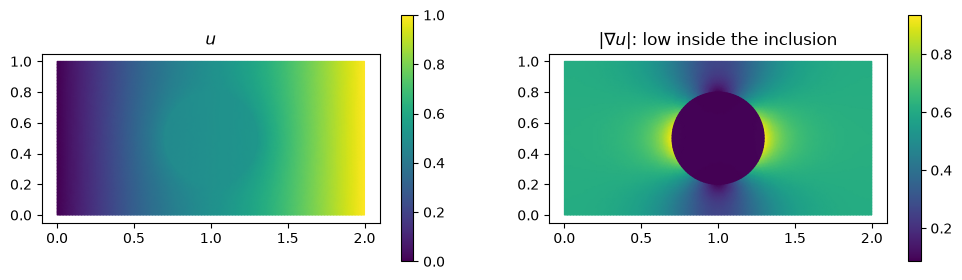

In [3]:
V2 = FunctionSpace(mesh2, "CG", 3)
u, v = TrialFunction(V2), TestFunction(V2)
k_in, k_out = 10.0, 1.0

a = k_in * inner(grad(u), grad(v)) * dx("inner") + k_out * inner(grad(u), grad(v)) * dx("outer")
L = Constant(0.0) * v * dx

bcs = [DirichletBC(V2, 0.0, "left"), DirichletBC(V2, 1.0, "right")]
uh2 = Function(V2, name="u")
solve(a == L, uh2, bcs=bcs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.2))
fig.colorbar(tripcolor(uh2, axes=ax1), ax=ax1)
ax1.set_title("$u$")
fig.colorbar(tripcolor(sqrt(inner(grad(uh2), grad(uh2))), axes=ax2), ax=ax2)
ax2.set_title("$|\\nabla u|$: low inside the inclusion")
for ax in (ax1, ax2):
    ax.set_aspect("equal")

### Checks

In steady state, the flux through the left side equals the flux through the right side.  We
compute both from the solution as boundary integrals of $-k\,\partial_n u$.  The
conductivity there is the outer one.  Then we compare the solution with a plain NGSolve
computation (an ngsufl extra: `mesh.ngs` is the NGSolve mesh), where the material
coefficient is built from the mesh materials.

In [4]:
n2 = FacetNormal(mesh2)
flux_left = assemble(-k_out * dot(grad(uh2), n2) * ds("left"))
flux_right = assemble(-k_out * dot(grad(uh2), n2) * ds("right"))
print("flux through left :", flux_left)
print("flux through right:", flux_right)
print("sum (should vanish):", flux_left + flux_right)

flux through left : 0.6144918749375847
flux through right: -0.6144923056874226
sum (should vanish): -4.307498379096941e-07


In [5]:
import ngsolve as ngs

m = mesh2.ngs
fes = ngs.H1(m, order=3, dirichlet="left|right")
w, wt = fes.TnT()
kappa = m.MaterialCF({"inner": k_in, "outer": k_out}, default=1)
A = ngs.BilinearForm(kappa * ngs.grad(w) * ngs.grad(wt) * ngs.dx).Assemble()
gf = ngs.GridFunction(fes)
gf.Set(m.BoundaryCF({"right": 1}, default=0), ngs.BND)
rhs = gf.vec.CreateVector()
rhs.data = -A.mat * gf.vec
gf.vec.data += A.mat.Inverse(fes.FreeDofs()) * rhs
print("native u at (1.9, 0.5):", gf(m(1.9, 0.5)), " ngsufl:", uh2.at(1.9, 0.5))
print("difference to native NGSolve (L2):", ngs.sqrt(ngs.Integrate((gf - to_cf(uh2))**2, m)))

native u at (1.9, 0.5): 0.9379604644203817  ngsufl: 0.9379604644841553
difference to native NGSolve (L2): 1.7983551765432318e-08


## Part 3: a Dirichlet condition on one component

For vector valued unknowns a boundary condition may fix only some components.  `V.sub(i)`
gives the $i$-th component as a subspace that can be used in `DirichletBC`.  As an
example take a plane stress elastic block $(0,2)\times(0,1)$ under uniaxial tension
$\sigma$ on the right side (2).  We only fix the normal displacement on the symmetry sides,
$u_x = 0$ on side 1 ($x = 0$) and $u_y = 0$ on side 3 ($y = 0$), and leave everything else free.  The
exact solution is homogeneous,

$$ u_x = \frac{\sigma}{E}\,x, \qquad u_y = -\frac{\nu\sigma}{E}\,y . $$

In [6]:
mesh3 = RectangleMesh(8, 4, 2.0, 1.0)
W = VectorFunctionSpace(mesh3, "CG", 2)
u, v = TrialFunction(W), TestFunction(W)

E, nu, sigma0 = 10.0, 0.3, 1.0
mu = E / (2 * (1 + nu))
lmbda = E * nu / (1 - nu**2)          # plane stress


def eps(w):
    return sym(grad(w))


def sigma(w):
    return 2 * mu * eps(w) + lmbda * tr(eps(w)) * Identity(2)


a = inner(sigma(u), eps(v)) * dx
L = dot(Constant((sigma0, 0.0)), v) * ds(2)

bcs = [DirichletBC(W.sub(0), 0.0, 1), DirichletBC(W.sub(1), 0.0, 3)]
wh = Function(W, name="u")
solve(a == L, wh, bcs=bcs)

x3 = SpatialCoordinate(mesh3)
w_exact = as_vector((sigma0 / E * x3[0], -nu * sigma0 / E * x3[1]))
print("L2 error:", errornorm(w_exact, wh))
print("u_x at (2, 1):", wh.at(2.0, 1.0)[0], " exact:", 2 * sigma0 / E)
print("u_y at (2, 1):", wh.at(2.0, 1.0)[1], " exact:", -nu * sigma0 / E)

L2 error: 6.915608416756634e-16
u_x at (2, 1): 0.1999999999999993  exact: 0.2
u_y at (2, 1): -0.029999999999999836  exact: -0.03


The solution is reproduced to round-off.  Had we fixed both components on the left side,
the clamp would suppress the lateral contraction there and the solution would be
non-homogeneous.